In [ ]:
from google.colab import drive
drive.mount('/content/drive')


MessageError: Error: credential propagation was unsuccessful

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:

import os

drive_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(drive_path):
    for name in files:
        if name.lower().endswith(".zip") and "caries" in name.lower():
            print(os.path.join(root, name))


/content/drive/MyDrive/Dental caries.v6i.yolov8.zip


In [ ]:

import zipfile
import os

zip_path = "/content/drive/MyDrive/Dental caries.v6i.yolov8.zip"
dataset_path = "/content/dental_dataset"

os.makedirs(dataset_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(dataset_path)

print("Extraction complete!")
print(os.listdir(dataset_path))


Extraction complete!
['README.roboflow.txt', 'train', 'data.yaml', 'test', 'README.dataset.txt', 'valid']


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 49.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 8.7 MB/s eta 0:00:00


In [ ]:

import os
import yaml

dataset_path = "/content/dental_dataset"
yaml_path = os.path.join(dataset_path, "data.yaml")

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

data["path"] = dataset_path
data["train"] = "train/images"
data["val"] = "valid/images"
data["test"] = "test/images"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print("Classes:", data["names"])
print("Train folder:", os.path.isdir(
    os.path.join(dataset_path, "train/images")))
print("Validation folder:", os.path.isdir(
    os.path.join(dataset_path, "valid/images")))
print("Test folder:", os.path.isdir(
    os.path.join(dataset_path, "test/images")))
print("Drive connected:", os.path.isdir(
    "/content/drive/MyDrive"))


Classes: ['Caries', 'Tooth']
Train folder: True
Validation folder: True
Test folder: True
Drive connected: True


In [ ]:

from ultralytics import YOLO
import os

# Save all training results in Google Drive
project_dir = "/content/drive/MyDrive/DentalLoupes"

os.makedirs(project_dir, exist_ok=True)

# Load pretrained YOLOv8 nano model
model = YOLO("yolov8n.pt")

# Start training
results = model.train(
    data="/content/dental_dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    project=project_dir,
    name="dental_caries",
    patience=10,
    save=True,
    save_period=1
)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dental_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1

In [ ]:

import os

weights_dir = (
    "/content/drive/MyDrive/DentalLoupes/"
    "dental_caries/weights"
)

print("Weights folder exists:", os.path.isdir(weights_dir))

if os.path.isdir(weights_dir):
    print("Saved files:", os.listdir(weights_dir))


Weights folder exists: True
Saved files: ['last.pt', 'best.pt', 'epoch0.pt', 'epoch1.pt', 'epoch2.pt', 'epoch3.pt', 'epoch4.pt', 'epoch5.pt', 'epoch6.pt', 'epoch7.pt', 'epoch8.pt', 'epoch9.pt', 'epoch10.pt', 'epoch11.pt', 'epoch12.pt', 'epoch13.pt', 'epoch14.pt', 'epoch15.pt', 'epoch16.pt', 'epoch17.pt', 'epoch18.pt', 'epoch19.pt', 'epoch20.pt', 'epoch21.pt', 'epoch22.pt', 'epoch23.pt', 'epoch24.pt', 'epoch25.pt', 'epoch26.pt', 'epoch27.pt', 'epoch28.pt', 'epoch29.pt', 'epoch30.pt', 'epoch31.pt', 'epoch32.pt', 'epoch33.pt', 'epoch34.pt', 'epoch35.pt', 'epoch36.pt', 'epoch37.pt', 'epoch38.pt', 'epoch39.pt', 'epoch40.pt', 'epoch41.pt', 'epoch42.pt', 'epoch43.pt', 'epoch44.pt', 'epoch45.pt', 'epoch46.pt', 'epoch47.pt', 'epoch48.pt', 'epoch49.pt']


In [ ]:

from google.colab import files
from ultralytics import YOLO
from IPython.display import display
from PIL import Image

# Load your trained model from Google Drive
model_path = (
    "/content/drive/MyDrive/DentalLoupes/"
    "dental_caries/weights/best.pt"
)

model = YOLO(model_path)
print("Dental caries model loaded successfully!")

# Upload a dental image
uploaded = files.upload()

# Detect and display results
for filename in uploaded:
    results = model.predict(
        source=filename,
        conf=0.25,
        save=True
    )

    annotated_image = results[0].plot()
    display(Image.fromarray(annotated_image[:, :, ::-1]))

    print("Detected objects:")
    print(results[0].boxes)


Dental caries model loaded successfully!


KeyboardInterrupt: 

Test images found: 199
Testing image: /content/dental_dataset/test/images/2771_jpg.rf.8e825b0dd5fecc31a7e8edd85a86849b.jpg

image 1/1 /content/dental_dataset/test/images/2771_jpg.rf.8e825b0dd5fecc31a7e8edd85a86849b.jpg: 640x640 7 Tooths, 18.4ms
Speed: 2.2ms preprocess, 18.4ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)


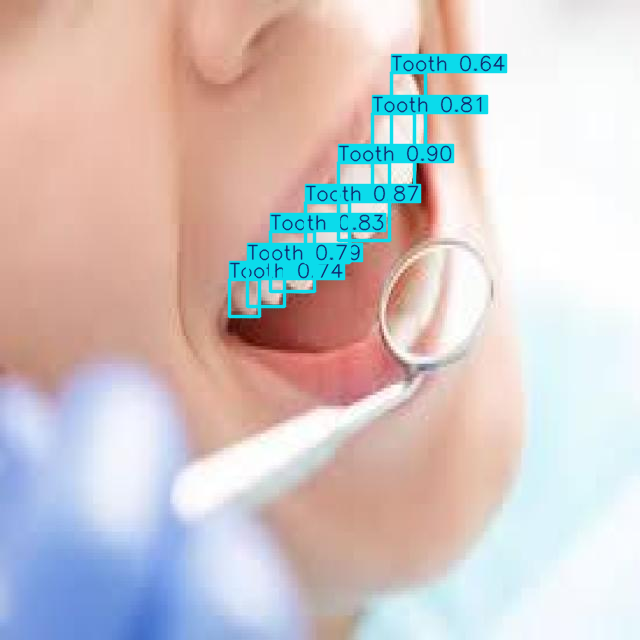

In [ ]:

import glob
from ultralytics import YOLO
from IPython.display import display
from PIL import Image

model_path = "/content/drive/MyDrive/DentalLoupes/dental_caries/weights/best.pt"
test_folder = "/content/dental_dataset/test/images"

images = []
for ext in ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]:
    images.extend(glob.glob(f"{test_folder}/{ext}"))

print("Test images found:", len(images))

if images:
    model = YOLO(model_path)
    image_path = images[0]
    print("Testing image:", image_path)

    result = model.predict(image_path, conf=0.25)[0]
    display(Image.fromarray(result.plot()[:, :, ::-1]))
else:
    print("No images found. Check the test folder path.")


In [ ]:

import glob
from collections import Counter
from ultralytics import YOLO

model_path = (
    "/content/drive/MyDrive/DentalLoupes/"
    "dental_caries/weights/best.pt"
)

test_folder = "/content/dental_dataset/test/images"

images = []
for ext in ["*.jpg", "*.jpeg", "*.png"]:
    images.extend(glob.glob(f"{test_folder}/{ext}"))

model = YOLO(model_path)
counts = Counter()

for image_path in images[:50]:
    result = model.predict(
        source=image_path,
        conf=0.15,
        verbose=False
    )[0]

    for cls_id in result.boxes.cls.tolist():
        counts[model.names[int(cls_id)]] += 1

print("Images tested:", min(50, len(images)))
print("Detections by class:", dict(counts))
print("Caries detections:", counts.get("Caries", 0))
print("Tooth detections:", counts.get("Tooth", 0))


Images tested: 50
Detections by class: {'Tooth': 527, 'Caries': 128}
Caries detections: 128
Tooth detections: 527


In [ ]:

from ultralytics import YOLO

model_path = (
    "/content/drive/MyDrive/DentalLoupes/"
    "dental_caries/weights/best.pt"
)

model = YOLO(model_path)

metrics = model.val(
    data="/content/dental_dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True
)

print("Test Precision:", metrics.box.mp)
print("Test Recall:", metrics.box.mr)
print("Test mAP50:", metrics.box.map50)
print("Test mAP50-95:", metrics.box.map)


Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 241.6±296.4 MB/s, size: 31.0 KB)
val: Scanning /content/dental_dataset/test/labels... 199 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 199/199 702.6it/s 0.3s
val: New cache created: /content/dental_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 5.4it/s 4.6s
                   all        199       2029       0.64      0.675      0.656      0.507
                Caries         98        340      0.436      0.385      0.346      0.166
                 Tooth        198       1689      0.844      0.964      0.966      0.849
Speed: 2.7ms preprocess, 6.9ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /content/runs/detect/val
Test Precision: 0.6399923791477927
Te

In [ ]:

from google.colab.output import eval_js
from IPython.display import display, Javascript
from ultralytics import YOLO
from PIL import Image
from base64 import b64decode
import io
import os

# 1. Load your trained model from Google Drive
model_path = "/content/drive/MyDrive/DentalLoupes/dental_caries/weights/best.pt"

if not os.path.exists(model_path):
    raise FileNotFoundError(
        "Model not found. Check the path to your best.pt file."
    )

model = YOLO(model_path)
print("Dental caries model loaded successfully!")

# 2. Open your laptop camera and capture one image
display(Javascript("""
async function captureDentalImage() {
    const video = document.createElement('video');
    const stream = await navigator.mediaDevices.getUserMedia({
        video: true
    });

    video.srcObject = stream;
    video.autoplay = true;
    video.playsInline = true;
    video.style.width = '480px';
    document.body.appendChild(video);

    await new Promise(resolve => {
        video.onloadedmetadata = resolve;
    });
    await video.play();

    // Allow time to position yourself
    await new Promise(resolve => setTimeout(resolve, 3000));

    const canvas = document.createElement('canvas');
    canvas.width = video.videoWidth;
    canvas.height = video.videoHeight;
    canvas.getContext('2d').drawImage(video, 0, 0);

    stream.getTracks().forEach(track => track.stop());
    video.remove();

    return canvas.toDataURL('image/jpeg', 0.95);
}
"""))

print("Allow camera permission when your browser asks.")
print("Position your teeth in front of the camera...")

data = eval_js("captureDentalImage()")

# 3. Convert captured photo into an image
image = Image.open(
    io.BytesIO(b64decode(data.split(",")[1]))
).convert("RGB")

print("Image captured successfully!")
display(image)

# 4. Detect teeth and possible caries
result = model.predict(
    source=image,
    imgsz=640,
    conf=0.25,
    verbose=False
)[0]

annotated = Image.fromarray(result.plot()[:, :, ::-1])

print("Detection completed!")
display(annotated)

# 5. Display predicted classes and confidence scores
if result.boxes is not None and len(result.boxes) > 0:
    for box in result.boxes:
        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())
        class_name = result.names[class_id]

        print(f"{class_name}: {confidence:.2%} confidence")
else:
    print("No objects detected in this captured image.")


ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 7.0 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
from PIL import Image
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from io import BytesIO

print("Libraries imported successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

search_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(search_path):
    if "best.pt" in files:
        print(os.path.join(root, "best.pt"))

In [ ]:
import os

search_path = "/content/drive/MyDrive"

matches = []

for root, dirs, files in os.walk(search_path):
    if "best.pt" in files:
        matches.append(os.path.join(root, "best.pt"))

if matches:
    print("Model files found:")
    for path in matches:
        print(path)
else:
    print("No best.pt found in MyDrive.")

No best.pt found in MyDrive.


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for name in files:
        if name.endswith((".pt", ".onnx")):
            print(os.path.join(root, name))

In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for name in files:
        if name.endswith((".pt", ".onnx")):
            print(os.path.join(root, name))

In [ ]:
import os

print("Drive connected:", os.path.exists("/content/drive/MyDrive"))
print("DentalLoupes folder exists:",
      os.path.exists("/content/drive/MyDrive/DentalLoupes"))

for root, dirs, files in os.walk("/content/drive/MyDrive/DentalLoupes"):
    for name in files:
        if name.endswith((".pt", ".onnx")):
            print("MODEL FOUND:", os.path.join(root, name))

Drive connected: False
DentalLoupes folder exists: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

ValueError: mount failed

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import os

drive_path = "/content/drive/MyDrive"

print("Google Drive files and folders:")
print(os.listdir(drive_path))

print("\nSearching for trained YOLO model weights...")

for root, dirs, files in os.walk(drive_path):
    for name in files:
        if name in ["best.pt", "last.pt"]:
            print("FOUND:", os.path.join(root, name))


Google Drive files and folders:
['Colab Notebooks', 'Screenshot_20250328_125933.jpg', '1000027682.jpg', 'Diploma Marksheet.pdf', 'IMG_20250221_130324.jpg', 'Classroom', 'Assignment No-01 (2).pdf', 'Assignment No-01 (1).pdf', 'Assignment No-01.pdf', 'Prac 3 books.gdoc', 'prajkta salgar (1).pdf', 'wokwi-project.gdoc', 'Screenshot_20250201_105058.jpg', 'IMG_20250220_170003.jpg', 'Untitled form.gform', 'Document from ✨ (25)', 'Diploma Marksheet_compressed.pdf', 'Document from ✨ (24)', 'Document from ✨ (23)', 'Document from ✨ (22)', 'Document from ✨ (21)', 'Document from ✨ (20)', 'Document from ✨ (19)', 'Document from ✨ (18)', 'Document from ✨ (17)', 'Cn', 'Document from ✨ (4).pdf', 'Document from ✨ (3).pdf', 'prajkta Salgar.pdf', 'Document from ✨ (16)', 'ppt[RAJKTA.gslides', 'ppt[RAJKTA.pptx', 'Document from ✨ (2).pdf', 'TE_C_10_PRAJKTA SALGAR_06.pdf', 'TE_C_10_PRAJKTA SALGAR_05.pdf', 'TE_C_10_ORAJKTA SALGAR_04.pdf', 'TE_C_10_PRAJKTA SALGAR -3.pdf', 'TE_C_10_PRAJKTA SALGAR ASSIGNMENT -3.pd

In [ ]:

%pip install -q ultralytics

from ultralytics import YOLO

model_path = "/content/drive/MyDrive/DentalLoupes/dental_caries/weights/best.pt"

model = YOLO(model_path)

print("Dental caries model loaded successfully!")
print("Classes:", model.names)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 5.3 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Dental caries model loaded successfully!
Classes: {0: 'Caries', 1: 'Tooth'}


In [ ]:

from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from PIL import Image
from io import BytesIO
import numpy as np

display(Javascript("""
(async () => {
  const box = document.createElement('div');
  const video = document.createElement('video');
  const btn = document.createElement('button');

  btn.textContent = 'Capture Photo';
  btn.style.cssText = 'padding:12px;font-size:18px;margin:10px';

  const stream = await navigator.mediaDevices.getUserMedia({video:true});
  video.srcObject = stream;
  video.autoplay = true;
  video.style.width = '480px';

  box.appendChild(video);
  box.appendChild(btn);
  document.body.appendChild(box);

  await new Promise(r => video.onloadedmetadata = r);
  await video.play();
  await new Promise(r => btn.onclick = r);

  const canvas = document.createElement('canvas');
  canvas.width = video.videoWidth;
  canvas.height = video.videoHeight;
  canvas.getContext('2d').drawImage(video,0,0);

  stream.getTracks().forEach(t => t.stop());
  box.remove();

  google.colab.kernel.invokeFunction(
    'notebook.save_photo',
    [canvas.toDataURL('image/jpeg')],
    {}
  );
})();
"""))


<IPython.core.display.Javascript object>

In [ ]:

from google.colab import output
from IPython.display import display, Javascript
from base64 import b64decode
from PIL import Image
from io import BytesIO

captured = {}

def save_photo(data):
    captured["image"] = Image.open(
        BytesIO(b64decode(data.split(",")[1]))
    ).convert("RGB")
    print("Photo captured successfully!")

output.register_callback("notebook.save_photo", save_photo)

display(Javascript("""
(async () => {
  try {
    const stream = await navigator.mediaDevices.getUserMedia({video:true});
    const video = document.createElement('video');
    const button = document.createElement('button');

    video.srcObject = stream;
    video.autoplay = true;
    video.style.width = '480px';
    button.textContent = 'Capture Photo';
    button.style.cssText = 'padding:12px;font-size:18px';

    document.body.append(video, button);
    await new Promise(resolve => video.onloadedmetadata = resolve);
    await video.play();
    await new Promise(resolve => button.onclick = resolve);

    const canvas = document.createElement('canvas');
    canvas.width = video.videoWidth;
    canvas.height = video.videoHeight;
    canvas.getContext('2d').drawImage(video,0,0);

    stream.getTracks().forEach(track => track.stop());
    video.remove();
    button.remove();

    await google.colab.kernel.invokeFunction(
      'notebook.save_photo',
      [canvas.toDataURL('image/jpeg')], {}
    );
  } catch (e) {
    alert('Camera error: ' + e.message +
          '. Check browser camera permission.');
  }
})();
"""))


<IPython.core.display.Javascript object>

Photo captured successfully!



0: 480x640 9 Tooths, 455.7ms
Speed: 26.9ms preprocess, 455.7ms inference, 46.7ms postprocess per image at shape (1, 3, 480, 640)


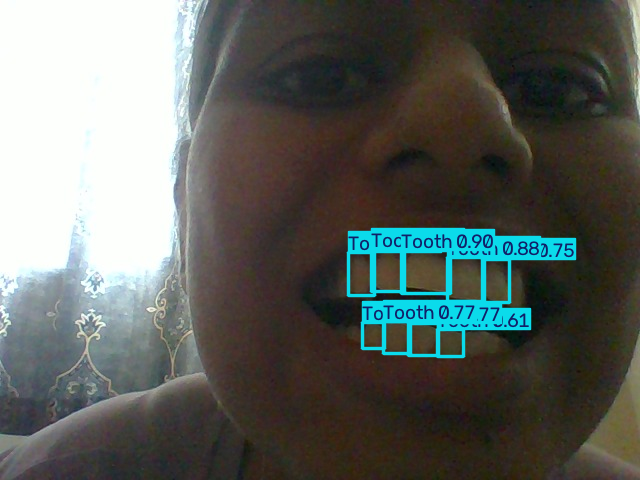

Tooth: 89.7%
Tooth: 88.4%
Tooth: 85.6%
Tooth: 76.7%
Tooth: 76.6%
Tooth: 75.4%
Tooth: 60.6%
Tooth: 59.4%
Tooth: 52.6%


In [ ]:

import numpy as np
import cv2
from google.colab.patches import cv2_imshow

# Convert the captured photo to OpenCV format
photo = cv2.cvtColor(
    np.array(captured["image"]),
    cv2.COLOR_RGB2BGR
)

# Run your trained dental detection model
results = model.predict(
    source=photo,
    conf=0.25,
    imgsz=640
)

# Display the image with detection boxes
annotated = results[0].plot()
cv2_imshow(annotated)

# Print detected classes and confidence
if len(results[0].boxes) > 0:
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(f"{model.names[class_id]}: {confidence:.1%}")
else:
    print("No objects detected. Try a clearer, well-lit photo.")


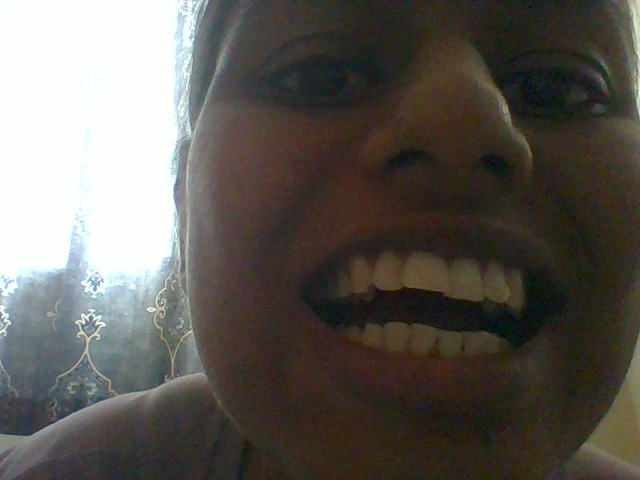

No caries detected in this image.


In [ ]:

# Detect cavities (Caries) only
results = model.predict(
    source=photo,
    conf=0.15,
    imgsz=640,
    classes=[0],
    verbose=False
)

annotated = results[0].plot()
cv2_imshow(annotated)

caries_found = False

for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    if model.names[class_id] == "Caries":
        caries_found = True
        print(f"Caries detected: {confidence:.1%} confidence")

if not caries_found:
    print("No caries detected in this image.")


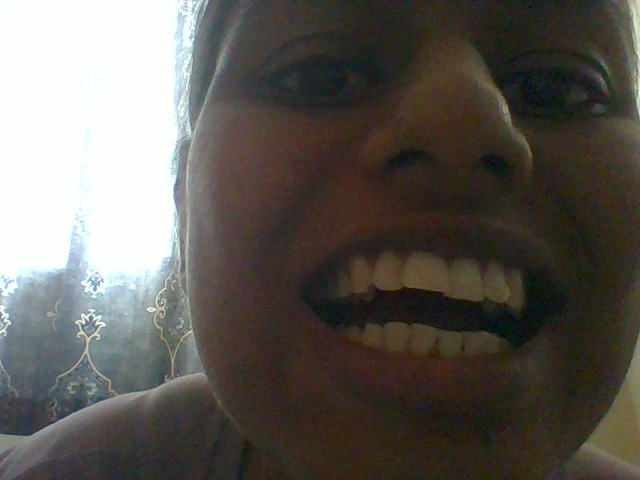

No caries detected in this image.


In [ ]:

# Detect cavities (Caries) only
results = model.predict(
    source=photo,
    conf=0.15,
    imgsz=640,
    classes=[0],
    verbose=False
)

annotated = results[0].plot()
cv2_imshow(annotated)

caries_found = False

for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    if model.names[class_id] == "Caries":
        caries_found = True
        print(f"Caries detected: {confidence:.1%} confidence")

if not caries_found:
    print("No caries detected in this image.")


In [ ]:

import numpy as np
import cv2
from google.colab.patches import cv2_imshow

# Convert the captured photo to OpenCV format
photo = cv2.cvtColor(
    np.array(captured["image"]),
    cv2.COLOR_RGB2BGR
)

# Run your trained dental detection model
results = model.predict(
    source=photo,
    conf=0.25,
    imgsz=640
)

# Display the image with detection boxes
annotated = results[0].plot()
cv2_imshow(annotated)

# Print detected classes and confidence
if len(results[0].boxes) > 0:
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(f"{model.names[class_id]}: {confidence:.1%}")
else:
    print("No objects detected. Try a clearer, well-lit photo.")


In [ ]:
from ultralytics import YOLO

model_path = "/content/drive/MyDrive/DentalLoupes/dental_caries/weights/best.pt"
model = YOLO(model_path)

print("Model loaded:", model.names)

Model loaded: {0: 'Caries', 1: 'Tooth'}


In [ ]:

from google.colab.output import eval_js
from IPython.display import display, Image
from base64 import b64decode
from PIL import Image as PILImage
from io import BytesIO
import cv2

# Make sure your trained model is loaded
# Run your existing model-loading cell first if needed.

# Open laptop camera and capture your teeth
camera_js = """
(async () => {
  const container = document.createElement('div');
  const video = document.createElement('video');
  const capture = document.createElement('button');

  capture.textContent = 'Capture My Teeth';
  capture.style.cssText =
      'font-size:18px;padding:12px;margin:10px;';

  video.setAttribute('autoplay', '');
  video.setAttribute('playsinline', '');
  video.style.width = '100%';
  video.style.maxWidth = '640px';

  container.appendChild(video);
  container.appendChild(capture);
  document.body.appendChild(container);

  let stream;

  try {
    stream = await navigator.mediaDevices.getUserMedia({
      video: true,
      audio: false
    });

    video.srcObject = stream;
    await video.play();

    await new Promise(resolve => {
      capture.onclick = resolve;
    });

    const canvas = document.createElement('canvas');
    canvas.width = video.videoWidth;
    canvas.height = video.videoHeight;
    canvas.getContext('2d').drawImage(video, 0, 0);

    return canvas.toDataURL('image/jpeg');
  } finally {
    if (stream) {
      stream.getTracks().forEach(track => track.stop());
    }
    container.remove();
  }
})()
"""

photo_data = eval_js(camera_js)

# Convert captured photo into an image
photo_bytes = b64decode(photo_data.split(",")[1])
photo = PILImage.open(BytesIO(photo_bytes)).convert("RGB")

print("Photo captured successfully!")
display(photo)

# Run your trained YOLO model
results = model.predict(
    source=photo,
    conf=0.25,
    imgsz=640
)

# Display image with detection boxes
annotated = results[0].plot()
annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

display(Image(data=cv2.imencode(
    ".jpg",
    cv2.cvtColor(annotated_rgb, cv2.COLOR_RGB2BGR)
)[1].tobytes()))

# Show detection results
if results[0].boxes is not None and len(results[0].boxes) > 0:
    print("\nDetection results:")

    for box in results[0].boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(f"{model.names[class_id]}: {confidence:.1%}")
else:
    print("No objects detected. Try better lighting and a clearer close-up.")


KeyboardInterrupt: 

In [ ]:
print("Model exists:", "model" in globals())
print("Camera code has started.")

In [ ]:
print("Colab is working!")
print("Model loaded:", "model" in globals())

Colab is working!
Model loaded: True



0: 480x640 9 Tooths, 184.0ms
Speed: 6.3ms preprocess, 184.0ms inference, 1.1ms postprocess per image at shape (1, 3, 480, 640)


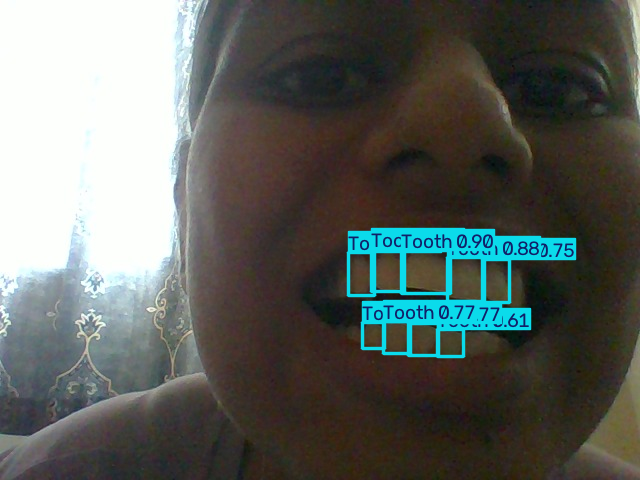

Tooth: 89.7%
Tooth: 88.4%
Tooth: 85.6%
Tooth: 76.7%
Tooth: 76.6%
Tooth: 75.4%
Tooth: 60.6%
Tooth: 59.4%
Tooth: 52.6%


In [ ]:

# Run the trained model on your captured photo
results = model.predict(
    source=photo,
    conf=0.25,
    imgsz=640
)

# Display the detection image
from IPython.display import display
import cv2
from PIL import Image as PILImage

annotated = results[0].plot()
annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
display(PILImage.fromarray(annotated))

# Print detected classes
if results[0].boxes is not None and len(results[0].boxes) > 0:
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(f"{model.names[class_id]}: {confidence:.1%}")
else:
    print("No objects detected. Try better lighting and a closer photo.")


New image captured successfully!


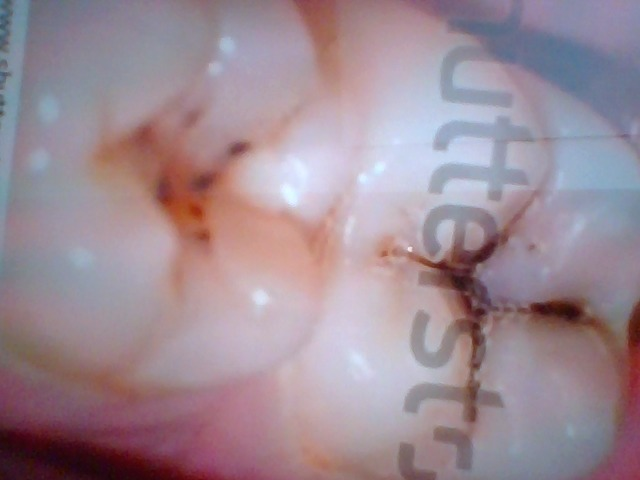

In [ ]:

from google.colab.output import eval_js
from base64 import b64decode
from IPython.display import display, Image
from PIL import Image as PILImage
from io import BytesIO

# Capture a new photo from your laptop camera
camera_js = """
(async () => {
  const stream = await navigator.mediaDevices.getUserMedia({
    video: true,
    audio: false
  });

  const video = document.createElement('video');
  video.srcObject = stream;
  video.style.width = '480px';
  document.body.appendChild(video);

  try {
    await video.play();

    await new Promise(resolve => setTimeout(resolve, 1500));

    if (!confirm('Ready to capture another image of your teeth?')) {
      return null;
    }

    const canvas = document.createElement('canvas');
    canvas.width = video.videoWidth;
    canvas.height = video.videoHeight;
    canvas.getContext('2d').drawImage(video, 0, 0);

    return canvas.toDataURL('image/jpeg');
  } finally {
    stream.getTracks().forEach(track => track.stop());
    video.remove();
  }
})()
"""

photo_data = eval_js(camera_js)

if photo_data:
    photo_bytes = b64decode(photo_data.split(",")[1])
    photo = PILImage.open(BytesIO(photo_bytes)).convert("RGB")

    print("New image captured successfully!")
    display(photo)
else:
    print("Capture cancelled.")



0: 480x640 7 Cariess, 2 Tooths, 169.2ms
Speed: 5.7ms preprocess, 169.2ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 640)


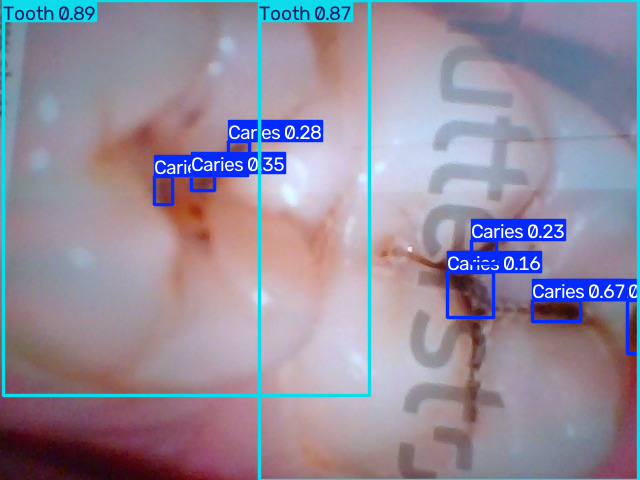


Detection results:
Tooth: 88.5%
Tooth: 87.1%
Caries: 67.0%
Caries: 35.0%
Caries: 27.8%
Caries: 25.2%
Caries: 23.2%
Caries: 19.6%
Caries: 16.1%


In [ ]:

# Run detection on the newly captured image stored in `photo`
results = model.predict(
    source=photo,
    conf=0.15,
    imgsz=640
)

# Display image with detection boxes
import cv2
from PIL import Image as PILImage
from IPython.display import display

annotated = results[0].plot()
annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
display(PILImage.fromarray(annotated_rgb))

# Print each detection
if results[0].boxes is not None and len(results[0].boxes) > 0:
    print("\nDetection results:")
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(f"{model.names[class_id]}: {confidence:.1%}")
else:
    print("No objects detected. Try a clearer, well-lit image.")


New image captured successfully!


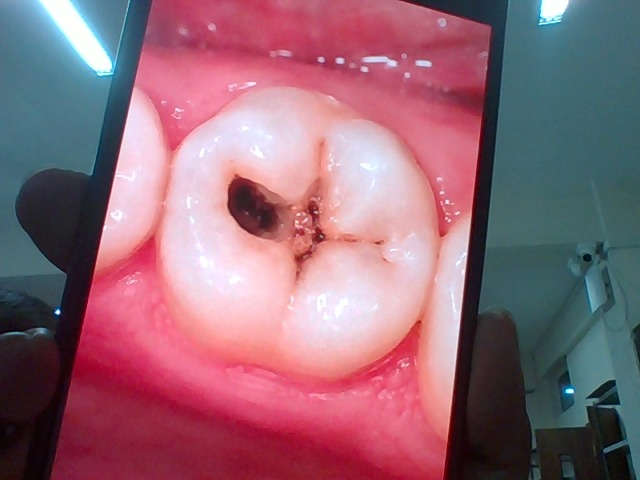

In [ ]:
from google.colab.output import eval_js
from base64 import b64decode
from IPython.display import display, Image
from PIL import Image as PILImage
from io import BytesIO

# Capture a new photo from your laptop camera
camera_js = """
(async () => {
  const stream = await navigator.mediaDevices.getUserMedia({
    video: true,
    audio: false
  });

  const video = document.createElement('video');
  video.srcObject = stream;
  video.style.width = '480px';
  document.body.appendChild(video);

  try {
    await video.play();

    await new Promise(resolve => setTimeout(resolve, 1500));

    if (!confirm('Ready to capture another image of your teeth?')) {
      return null;
    }

    const canvas = document.createElement('canvas');
    canvas.width = video.videoWidth;
    canvas.height = video.videoHeight;
    canvas.getContext('2d').drawImage(video, 0, 0);

    return canvas.toDataURL('image/jpeg');
  } finally {
    stream.getTracks().forEach(track => track.stop());
    video.remove();
  }
})()
"""

photo_data = eval_js(camera_js)

if photo_data:
    photo_bytes = b64decode(photo_data.split(",")[1])
    photo = PILImage.open(BytesIO(photo_bytes)).convert("RGB")

    print("New image captured successfully!")
    display(photo)
else:
    print("Capture cancelled.")


In [ ]:
from google.colab.output import eval_js
from IPython.display import display, Javascript

display(Javascript("""
(async () => {
  try {
    const stream = await navigator.mediaDevices.getUserMedia({
      video: true
    });
    stream.getTracks().forEach(track => track.stop());
    alert("Camera access works!");
  } catch (e) {
    alert("Camera error: " + e.name + " - " + e.message);
  }
})();
"""))

<IPython.core.display.Javascript object>

In [ ]:

# Run detection on the newly captured image stored in `photo`
results = model.predict(
    source=photo,
    conf=0.15,
    imgsz=640
)

# Display image with detection boxes
import cv2
from PIL import Image as PILImage
from IPython.display import display

annotated = results[0].plot()
annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
display(PILImage.fromarray(annotated_rgb))

# Print each detection
if results[0].boxes is not None and len(results[0].boxes) > 0:
    print("\nDetection results:")
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(f"{model.names[class_id]}: {confidence:.1%}")
else:
    print("No objects detected. Try a clearer, well-lit image.")


NameError: name 'model' is not defined

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

from ultralytics import YOLO
import os

model_path = "/content/drive/MyDrive/DentalLoupes/dental_caries/weights/best.pt"

print("Model file exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    model = YOLO(model_path)
    print("Model loaded successfully!")
    print("Classes:", model.names)
else:
    print("Model file not found. Check the Google Drive folder.")


Mounted at /content/drive


ModuleNotFoundError: No module named 'ultralytics'

In [ ]:

%pip install -q ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 11.7 MB/s eta 0:00:00


In [ ]:

from ultralytics import YOLO
import os

model_path = "/content/drive/MyDrive/DentalLoupes/dental_caries/weights/best.pt"

print("Model file exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    model = YOLO(model_path)
    print("Model loaded successfully!")
    print("Classes:", model.names)
else:
    print("Model file not found. Check the path.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model file exists: True
Model loaded successfully!
Classes: {0: 'Caries', 1: 'Tooth'}


In [ ]:

from google.colab.output import eval_js
from IPython.display import display, Javascript
from base64 import b64decode
from PIL import Image
from io import BytesIO

camera_js = Javascript("""
(async () => {
  const old = document.getElementById('dental-capture');
  if (old) old.remove();

  const box = document.createElement('div');
  box.id = 'dental-capture';
  const video = document.createElement('video');
  video.autoplay = true;
  video.playsInline = true;
  video.style.width = '480px';

  const button = document.createElement('button');
  button.textContent = 'Capture My Teeth';
  button.style.display = 'block';
  button.style.padding = '12px';

  box.appendChild(video);
  box.appendChild(button);
  document.body.appendChild(box);

  try {
    const stream = await navigator.mediaDevices.getUserMedia({
      video: { facingMode: 'user' }
    });
    video.srcObject = stream;
    await video.play();

    await new Promise(resolve => button.onclick = resolve);

    const canvas = document.createElement('canvas');
    canvas.width = video.videoWidth;
    canvas.height = video.videoHeight;
    canvas.getContext('2d').drawImage(video, 0, 0);

    stream.getTracks().forEach(track => track.stop());
    box.remove();

    return canvas.toDataURL('image/jpeg', 0.95).split(',')[1];
  } catch (e) {
    stream?.getTracks().forEach(track => track.stop());
    box.remove();
    throw e;
  }
})()
""")

photo_data = eval_js(camera_js.data)
photo = Image.open(BytesIO(b64decode(photo_data))).convert("RGB")
display(photo)
print("Image captured successfully!")


MessageError: ReferenceError: stream is not defined

In [ ]:

from google.colab.output import eval_js
from IPython.display import display, Javascript
from base64 import b64decode
from PIL import Image
from io import BytesIO

camera_js = Javascript("""
(async () => {
  const old = document.getElementById('dental-capture');
  if (old) old.remove();

  const box = document.createElement('div');
  box.id = 'dental-capture';
  const video = document.createElement('video');
  video.autoplay = true;
  video.playsInline = true;
  video.style.width = '480px';

  const button = document.createElement('button');
  button.textContent = 'Capture My Teeth';
  button.style.display = 'block';
  button.style.padding = '12px';

  box.appendChild(video);
  box.appendChild(button);
  document.body.appendChild(box);

  try {
    const stream = await navigator.mediaDevices.getUserMedia({
      video: { facingMode: 'user' }
    });
    video.srcObject = stream;
    await video.play();

    await new Promise(resolve => button.onclick = resolve);

    const canvas = document.createElement('canvas');
    canvas.width = video.videoWidth;
    canvas.height = video.videoHeight;
    canvas.getContext('2d').drawImage(video, 0, 0);

    stream.getTracks().forEach(track => track.stop());
    box.remove();

    return canvas.toDataURL('image/jpeg', 0.95).split(',')[1];
  } catch (e) {
    stream?.getTracks().forEach(track => track.stop());
    box.remove();
    throw e;
  }
})()
""")

photo_data = eval_js(camera_js.data)
photo = Image.open(BytesIO(b64decode(photo_data))).convert("RGB")
display(photo)
print("Image captured successfully!")
